<center><h1>Chen_Sian_HW5</h1></center>
<br>
<br>

Name: Sian Chen
<br>
Github Username: Ryan6546ea
<br>
USC ID: 3132413754

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
data = pd.read_csv(
    "../data/diagnosis.data",
    sep="\t", encoding="utf-16", decimal=",", header=None,
    names=[
        "temperature", "nausea", "lumbar_pain", "urine_pushing",
        "micturition_pain", "urethra_symptoms",
        "inflammation", "nephritis"
    ],
    true_values=["yes"], false_values=["no"]
)

print(data.shape)
data.head()

(120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_symptoms,inflammation,nephritis
0,35.5,False,True,False,False,False,False,False
1,35.9,False,False,True,True,True,True,False
2,35.9,False,True,False,False,False,False,False
3,36.0,False,False,True,True,True,True,False
4,36.0,False,True,False,False,False,False,False


### (b) Build a decision tree

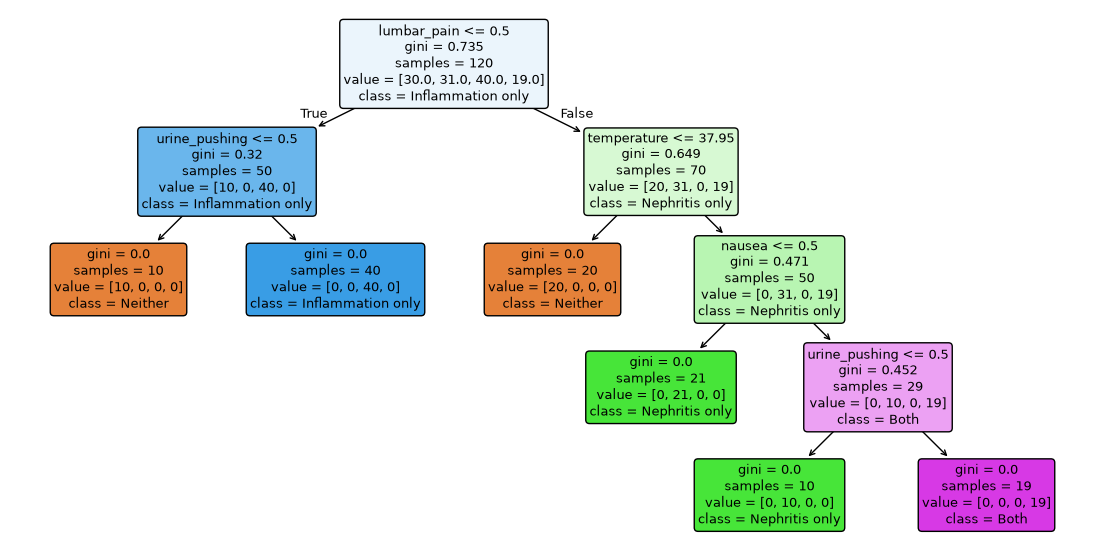

In [3]:
X = data.iloc[:, :6]
y = 2 * data["inflammation"].astype(int) + data["nephritis"].astype(int)
class_names = ["Neither", "Nephritis only", "Inflammation only", "Both"]

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X, y)

plt.figure(figsize=(14, 7))
plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.show()

### (c) Convert the decision rules

In [4]:
def print_rules(model, node=0, conditions=()):
    tree = model.tree_

    if tree.children_left[node] == tree.children_right[node]:
        label = model.classes_[tree.value[node][0].argmax()]
        rule = " AND ".join(conditions) or "TRUE"
        print(f"IF {rule} THEN {class_names[label]}")
        return

    feature = X.columns[tree.feature[node]]
    threshold = tree.threshold[node]

    print_rules(model, tree.children_left[node],
                conditions + (f"{feature} <= {threshold:.2f}",))
    print_rules(model, tree.children_right[node],
                conditions + (f"{feature} > {threshold:.2f}",))

print_rules(tree_model)

IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN Neither
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN Inflammation only
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN Neither
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea <= 0.50 THEN Nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN Nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50 THEN Both


### (d) Cost-complexity pruning

   Model    Alpha  Depth  Leaves  Training accuracy  Mean CV accuracy
Original 0.000000      4       6           1.000000          0.958333
  Pruned 0.098167      2       4           0.841667          0.775000

1-SE cutoff: 92.95%
Alpha selected by 1-SE: 0.000000


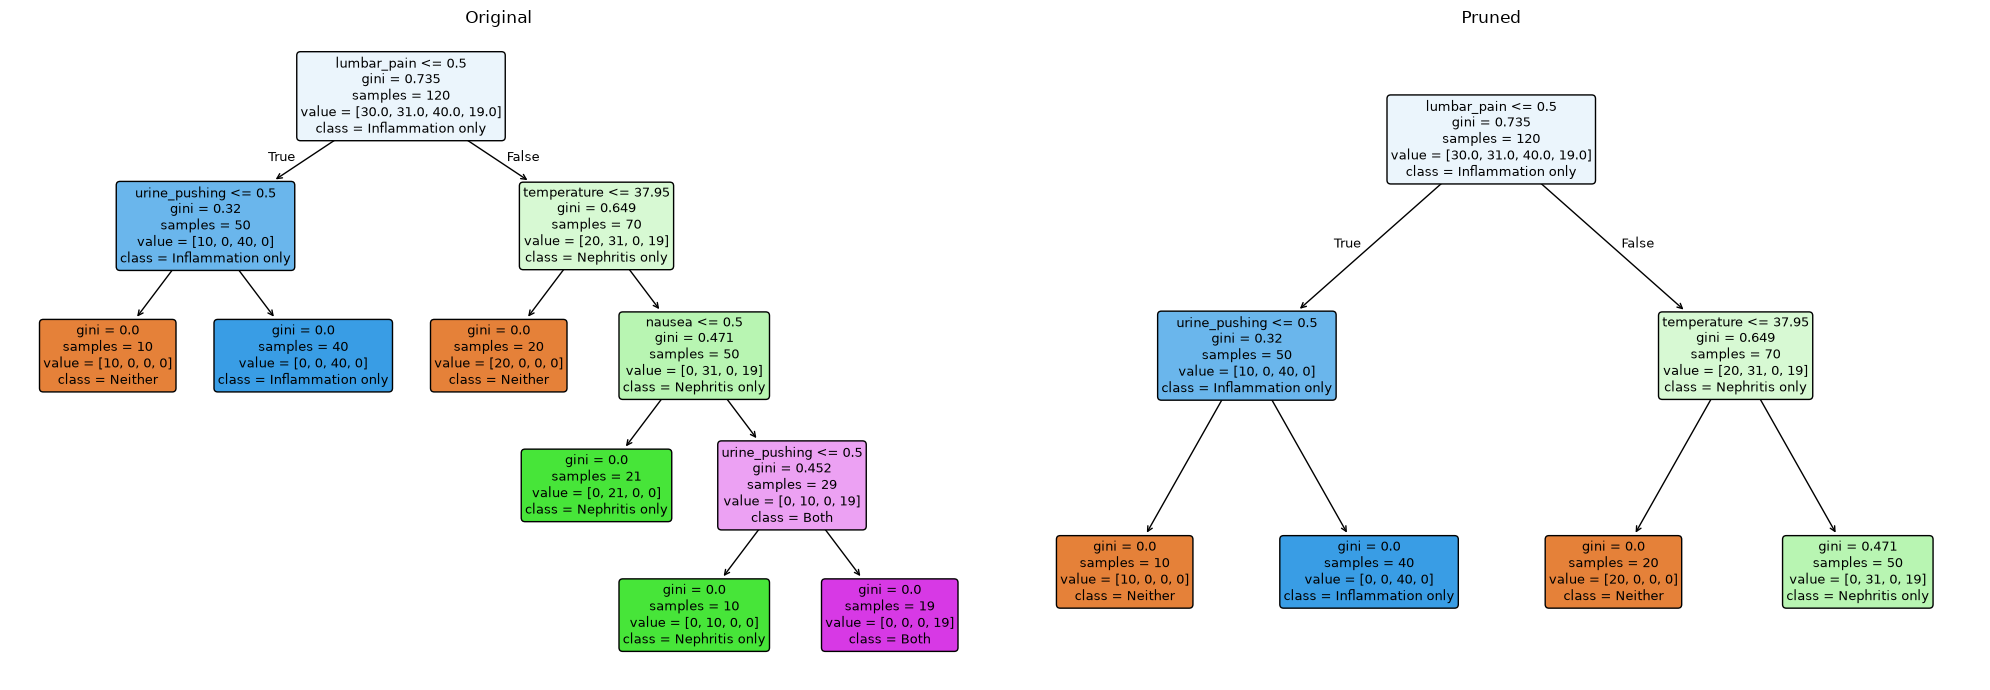


Rules for the pruned tree:
IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN Neither
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN Inflammation only
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN Neither
IF lumbar_pain > 0.50 AND temperature > 37.95 THEN Nephritis only


In [5]:
alphas = tree_model.cost_complexity_pruning_path(X, y).ccp_alphas

search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {"ccp_alpha": alphas},
    scoring="accuracy",
    cv=5,
    refit=False
).fit(X, y)

scores = search.cv_results_["mean_test_score"]
best = scores.argmax()
cutoff = scores[best] - search.cv_results_["std_test_score"][best] / np.sqrt(5)
selected_alpha = alphas[scores >= cutoff].max()

# Compare the original tree with the first actual pruning step.
pruned_index = np.flatnonzero(alphas > 0)[0]
pruned_alpha = alphas[pruned_index]
pruned_tree = DecisionTreeClassifier(
    random_state=42, ccp_alpha=pruned_alpha
).fit(X, y)

models = [tree_model, pruned_tree]
names = ["Original", "Pruned"]
comparison = pd.DataFrame({
    "Model": names,
    "Alpha": [0, pruned_alpha],
    "Depth": [model.get_depth() for model in models],
    "Leaves": [model.get_n_leaves() for model in models],
    "Training accuracy": [model.score(X, y) for model in models],
    "Mean CV accuracy": scores[[0, pruned_index]]
})

print(comparison.round(6).to_string(index=False))
print(f"\n1-SE cutoff: {cutoff:.2%}")
print(f"Alpha selected by 1-SE: {selected_alpha:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
for ax, name, model in zip(axes, names, models):
    plot_tree(
        model, feature_names=X.columns, class_names=class_names,
        filled=True, rounded=True, fontsize=9, ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

print("\nRules for the pruned tree:")
print_rules(pruned_tree)

At alpha = 0.098167, pruning reduces the depth from 4 to 2 and the number of rules from 6 to 4. Training accuracy falls from 100% to 84.17%. Mean five-fold CV accuracy falls from 95.83% to 77.50%. All 19 training cases with both conditions are predicted as nephritis only.
The 1-SE cutoff is 92.95%, so alpha = 0 is selected. I keep the original tree. It is the smallest candidate on this pruning path that meets the cutoff. The CV scores are used for model selection, not as independent test results.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [6]:
with open("../data/communities.names", encoding="utf-8") as f:
    columns = [line.split()[1] for line in f if line.startswith("@attribute")]

crime_data = pd.read_csv(
    "../data/communities.data",
    header=None,
    names=columns,
    na_values="?"
)

train_data = crime_data.iloc[:1495]
test_data = crime_data.iloc[1495:]

print("Full data:", crime_data.shape)
print("Training set:", train_data.shape)
print("Test set:", test_data.shape)

Full data: (1994, 128)
Training set: (1495, 128)
Test set: (499, 128)


### (b) Missing values

In [7]:
nonpredictive = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"

X_train = train_data.drop(columns=nonpredictive + [target])
X_test = test_data.drop(columns=nonpredictive + [target])
y_train = train_data[target]
y_test = test_data[target]

# Median imputation is less sensitive to extreme values.
imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Apply training-set medians to avoid test-set leakage.
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Training predictors:", X_train_imputed.shape)
print("Test predictors:", X_test_imputed.shape)
print("Missing after imputation (train, test):",
      X_train_imputed.isna().sum().sum(),
      X_test_imputed.isna().sum().sum())

Training predictors: (1495, 122)
Test predictors: (499, 122)
Missing after imputation (train, test): 0 0


### (c) Plot a correlation matrix

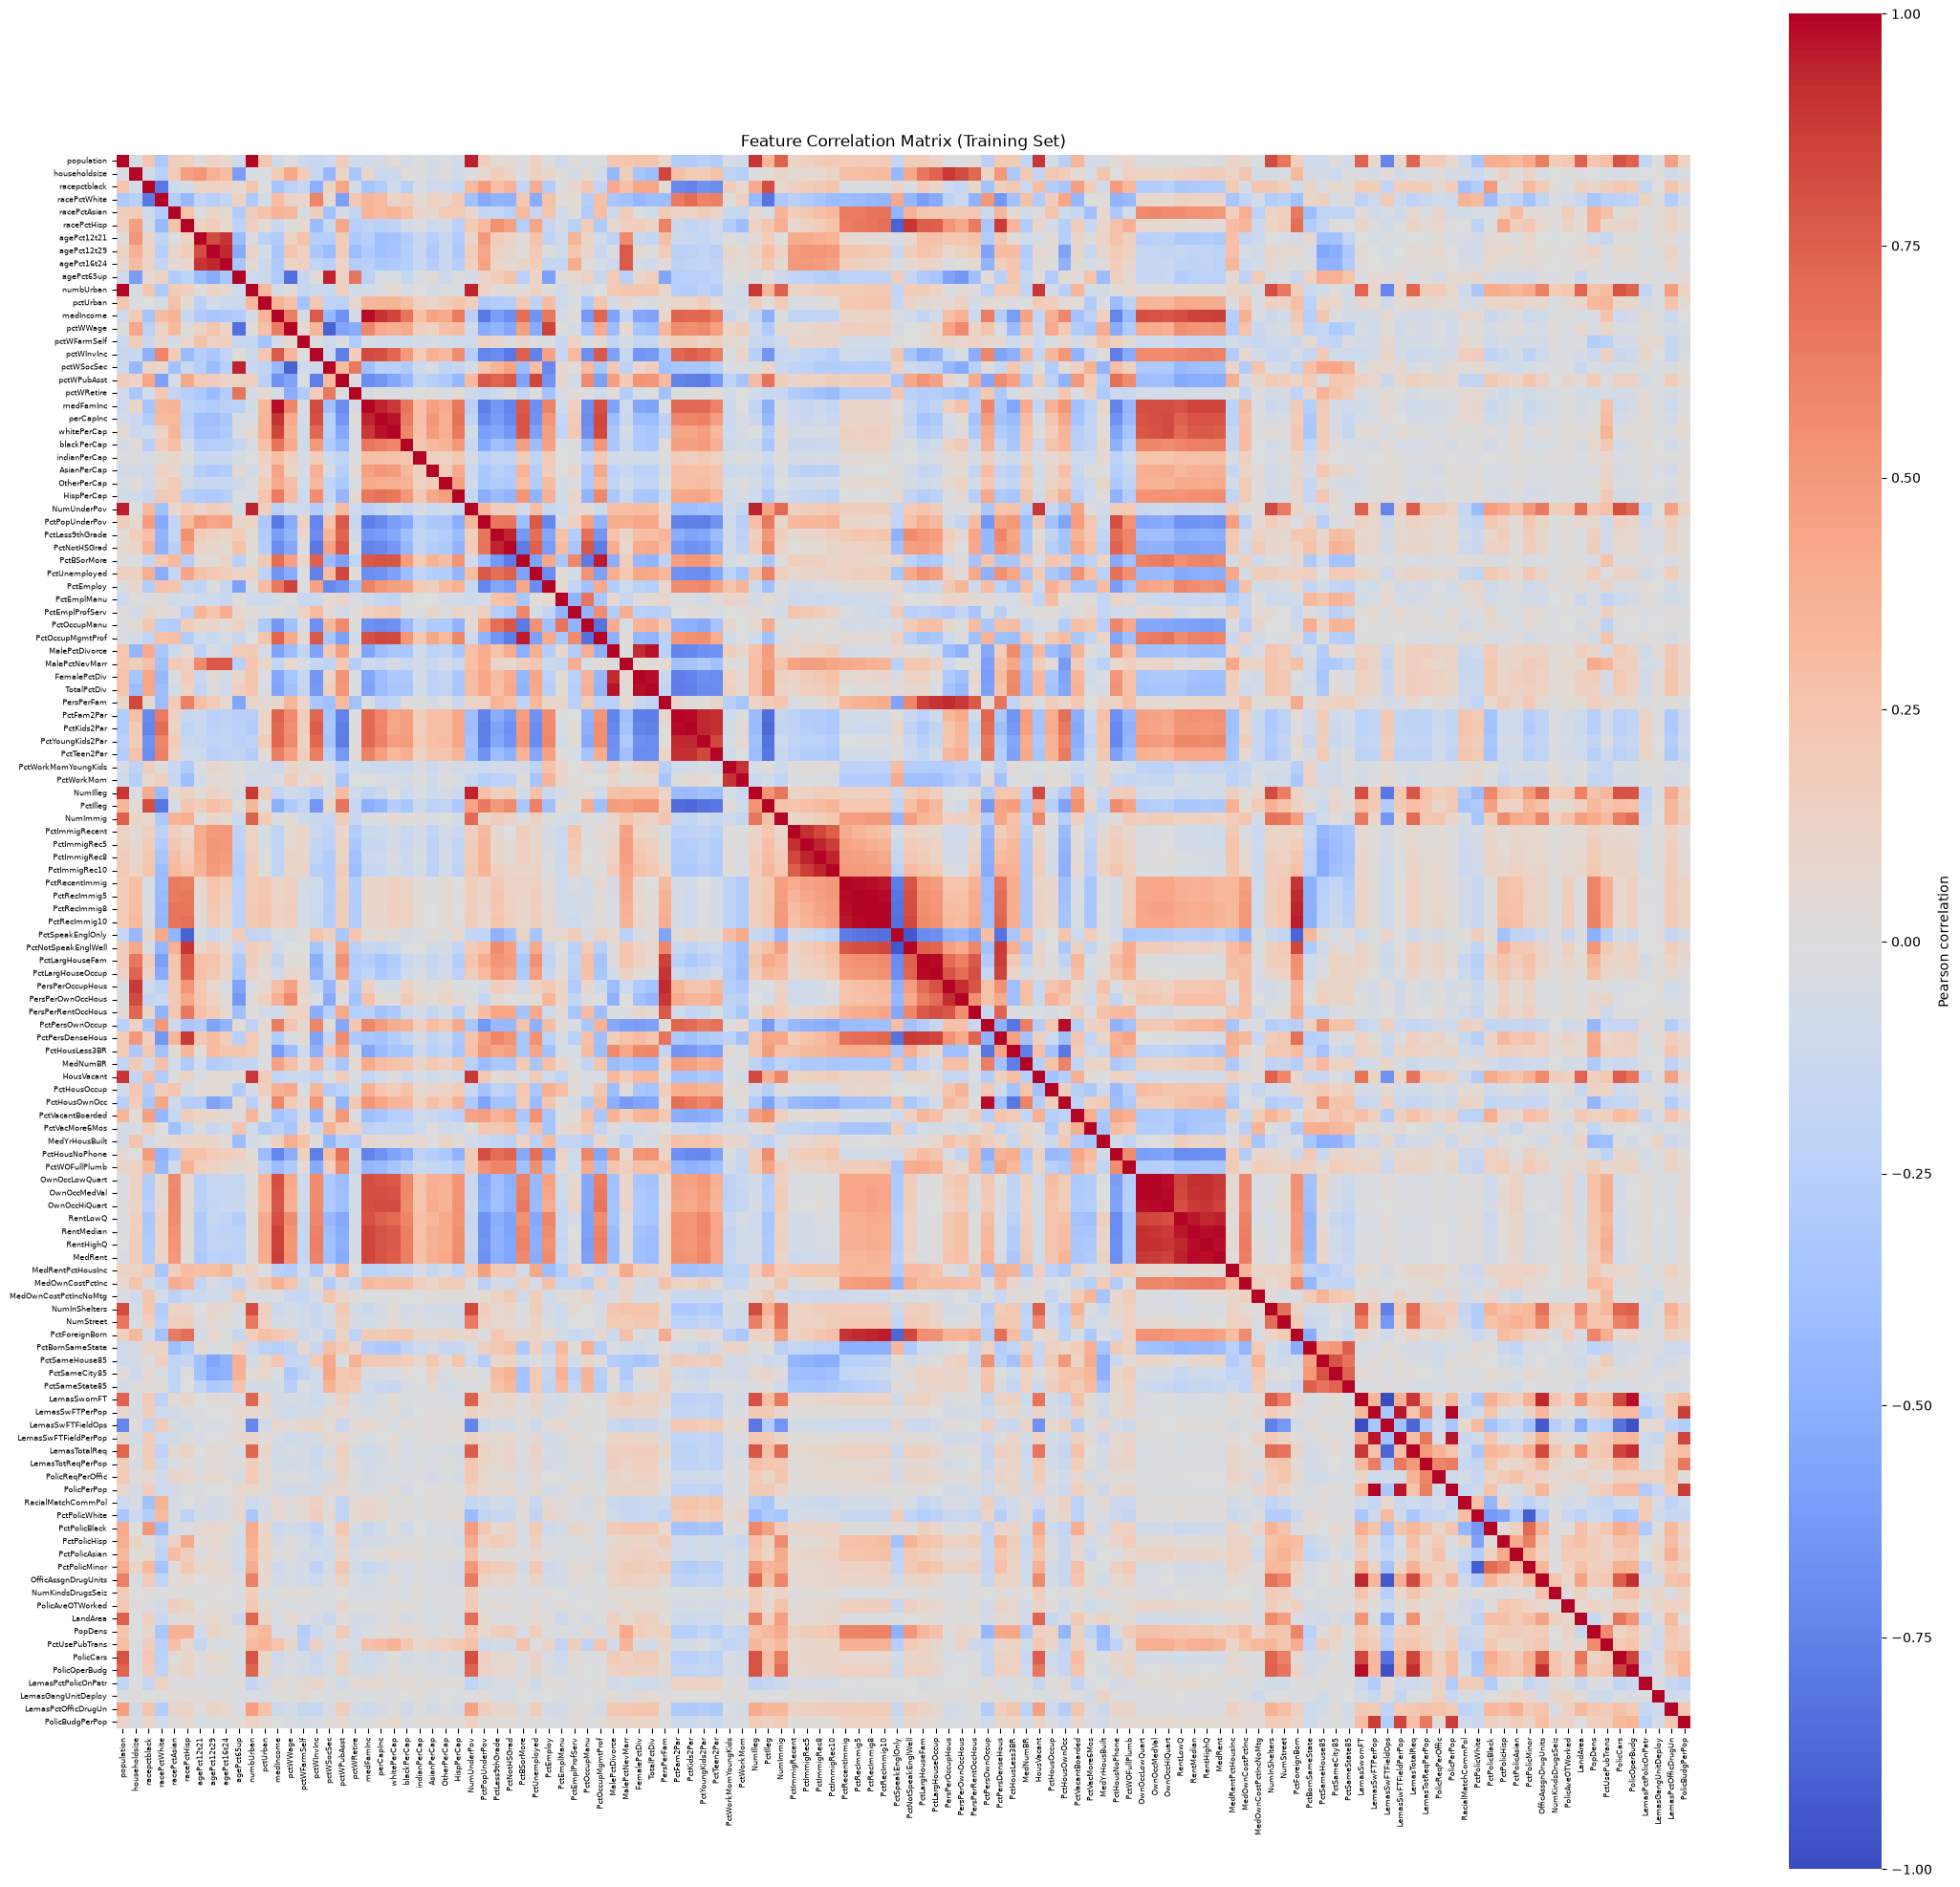

In [8]:
corr = X_train_imputed.corr()

plt.figure(figsize=(22, 20))
sns.heatmap(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"label": "Pearson correlation"}
)
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.title("Feature Correlation Matrix (Training Set)")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [9]:
# Use sample standard deviations and rank features for 2(e).
feature_cv = (
    X_train_imputed.std(ddof=1) / X_train_imputed.mean()
).sort_values(ascending=False)

print(feature_cv.to_string())

PctPolicAsian            5.527059
NumStreet                4.292923
NumInShelters            3.470952
NumIlleg                 3.058964
NumImmig                 2.926635
LemasPctOfficDrugUn      2.552946
NumUnderPov              2.342443
LemasSwornFT             2.248042
population               2.241105
numbUrban                2.038461
HousVacant               1.968467
PolicOperBudg            1.645508
LandArea                 1.645408
racePctHisp              1.612091
PctNotSpeakEnglWell      1.456618
LemasTotalReq            1.451887
racepctblack             1.428885
PctUsePubTrans           1.397110
racePctAsian             1.359100
PctPolicHisp             1.353882
PctRecentImmig           1.288287
PctRecImmig5             1.286184
PctRecImmig10            1.270476
PctRecImmig8             1.265579
OfficAssgnDrugUnits      1.174565
PctPersDenseHous         1.132926
PolicCars                1.112831
PctForeignBorn           1.065880
PctVacantBoarded         1.054827
PctHousNoPhone

### (e) Scatter plots and box plots for highest CV features

PctPolicAsian          5.527059
NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
NumUnderPov            2.342443
LemasSwornFT           2.248042
population             2.241105
numbUrban              2.038461
HousVacant             1.968467


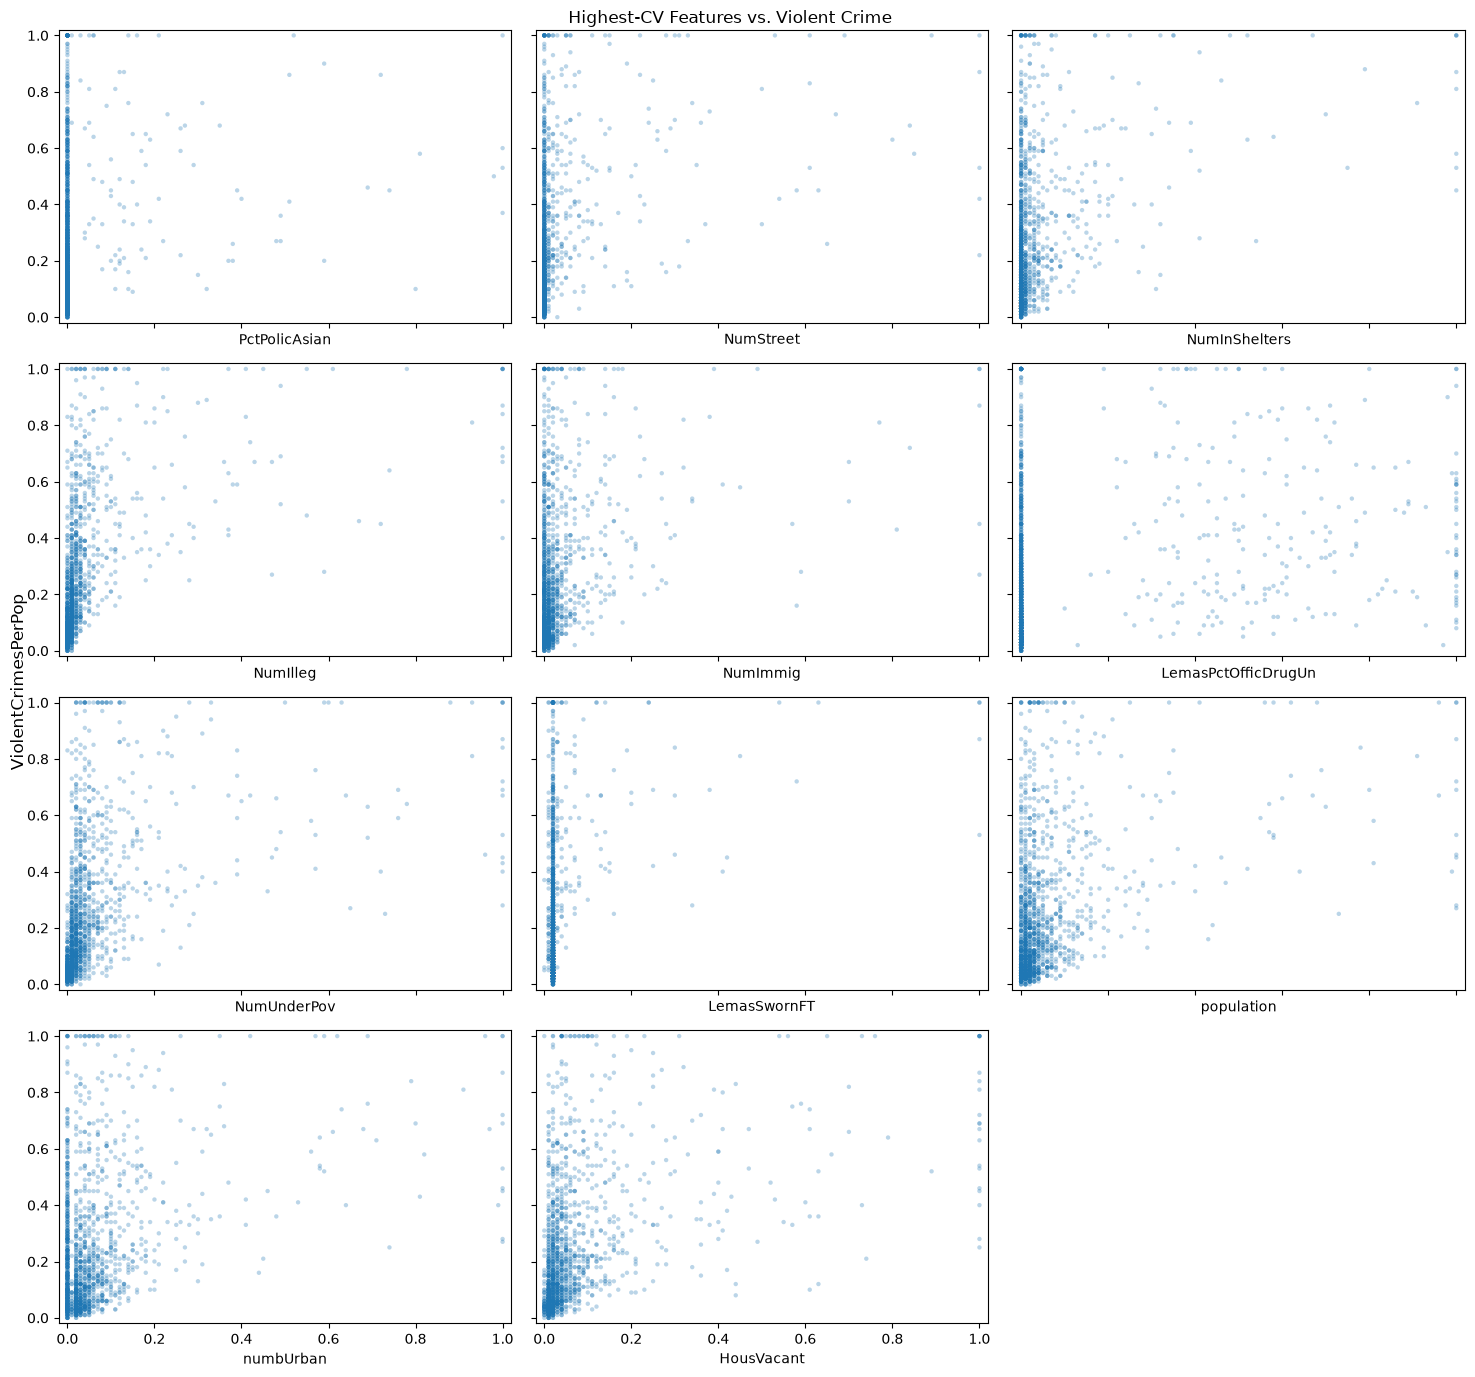

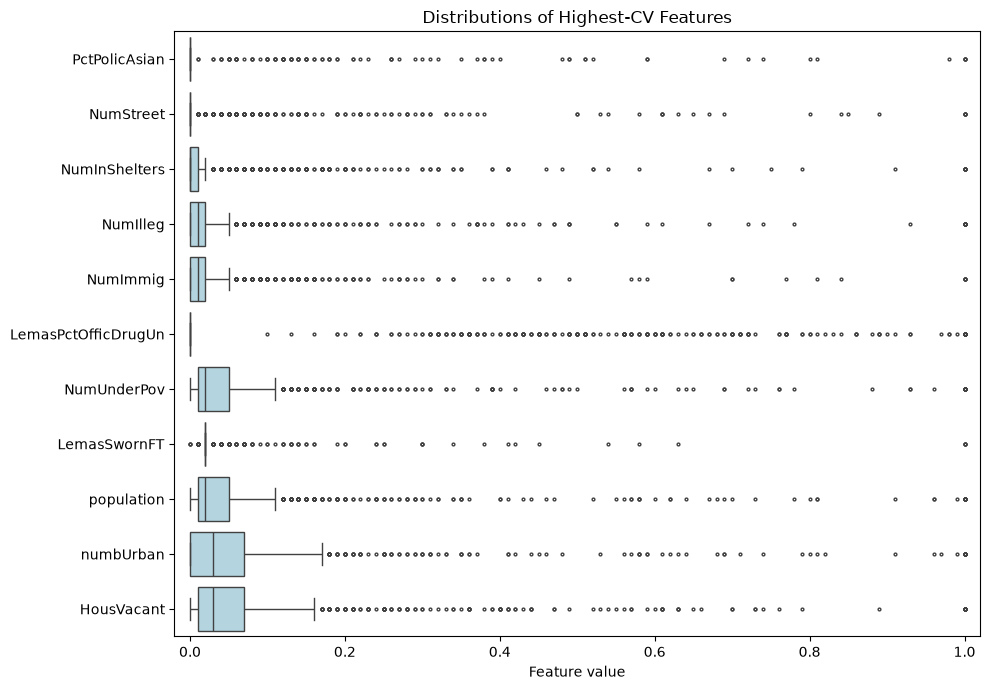

In [10]:
# Select 11 features for visualization only.
top_features = feature_cv.head(int(np.sqrt(128))).index
print(feature_cv.loc[top_features].to_string())

fig, axes = plt.subplots(4, 3, figsize=(15, 14), sharex=True, sharey=True)
for ax, feature in zip(axes.flat, top_features):
    ax.scatter(
        X_train_imputed[feature], y_train,
        s=10, alpha=0.3, edgecolors="none"
    )
    ax.set_xlabel(feature)

axes[-1, -1].set_visible(False)
axes[0, 0].set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
fig.supylabel("ViolentCrimesPerPop")
fig.suptitle("Highest-CV Features vs. Violent Crime")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
sns.boxplot(
    data=X_train_imputed[top_features],
    orient="h", color="lightblue", fliersize=2
)
plt.xlim(-0.02, 1.02)
plt.xlabel("Feature value")
plt.title("Distributions of Highest-CV Features")
plt.tight_layout()
plt.show()

PctPolicAsian has the highest CV (5.53). Most selected features are right-skewed, with many repeated values near zero. NumIlleg and NumUnderPov show positive associations with violent crime. Scatter plots alone cannot establish statistical significance or causation. High CV measures relative spread, not predictive importance.

### (f) Fit a linear model

In [11]:
ols = LinearRegression().fit(X_train_imputed, y_train)
ols_mse = mean_squared_error(y_test, ols.predict(X_test_imputed))

print(f"Test MSE: {ols_mse:.6f}")

Test MSE: 0.017966


The least-squares model has a test MSE of 0.017966.

### (g) Fit a ridge regression model

In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Fit preprocessing separately within each training fold.
def tune_model(model, param_grid):
    return GridSearchCV(
        model, param_grid, cv=cv,
        scoring="neg_mean_squared_error", n_jobs=4
    ).fit(X_train, y_train)

ridge = tune_model(
    make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge()),
    {"ridge__alpha": np.logspace(-4, 4, 25)}
)
ridge_mse = mean_squared_error(y_test, ridge.predict(X_test))

print(f"Selected lambda: {ridge.best_params_['ridge__alpha']:.6g}")
print(f"Test MSE: {ridge_mse:.6f}")

Selected lambda: 100
Test MSE: 0.017402


Cross-validation selected lambda = 100. The test MSE is 0.017402, slightly lower than the least-squares error.

### (h) Fit a LASSO model

In [13]:
lasso_models = {
    "Unstandardized": make_pipeline(
        SimpleImputer(strategy="median"), Lasso(max_iter=50000)
    ),
    "Standardized": make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(),
        Lasso(max_iter=50000)
    )
}

for name, model in lasso_models.items():
    fitted = tune_model(model, {"lasso__alpha": np.logspace(-5, 0, 31)})
    coefficients = fitted.best_estimator_.named_steps["lasso"].coef_
    selected = X_train.columns[coefficients != 0].tolist()
    mse = mean_squared_error(y_test, fitted.predict(X_test))

    print(f"\n{name}")
    print(f"Selected lambda: {fitted.best_params_['lasso__alpha']:.6g}")
    print(f"Test MSE: {mse:.6f}")
    print(f"Selected features ({len(selected)}): {selected}")


Unstandardized
Selected lambda: 0.0001
Test MSE: 0.017659
Selected features (75): ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShe

Without standardization, LASSO selected lambda = 0.0001 and retained 75 predictors. Its test MSE is 0.017659. With standardization, it selected lambda = 0.000681292 and retained 76 predictors. Its test MSE is 0.017707. Standardization did not improve test error on this split.

### (i) Fit a PCR model

In [14]:
pcr = tune_model(
    make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(),
        PCA(svd_solver="full"), LinearRegression()
    ),
    {"pca__n_components": range(1, X_train.shape[1] + 1)}
)
pcr_mse = mean_squared_error(y_test, pcr.predict(X_test))

print(f"Selected M: {pcr.best_params_['pca__n_components']}")
print(f"Test MSE: {pcr_mse:.6f}")

Selected M: 60
Test MSE: 0.018350


Cross-validation selected 60 principal components. The test MSE is 0.018350, higher than the least-squares error.

### (j) Fit a boosting tree

In [15]:
boost = tune_model(
    make_pipeline(
        SimpleImputer(strategy="median"),
        XGBRegressor(
            objective="reg:squarederror", n_estimators=300,
            max_depth=3, learning_rate=0.05, tree_method="hist",
            reg_lambda=0, random_state=42, n_jobs=1
        )
    ),
    {"xgbregressor__reg_alpha": np.r_[0, np.logspace(-3, 2, 11)]}
)
boost_mse = mean_squared_error(y_test, boost.predict(X_test))

print(f"Selected alpha: {boost.best_params_['xgbregressor__reg_alpha']:.6g}")
print(f"Test MSE: {boost_mse:.6f}")

Selected alpha: 0.316228
Test MSE: 0.016597


Cross-validation selected alpha = 0.316228. The test MSE is 0.016597, the lowest among the models evaluated on this test set.